In [39]:
# 06-08-2026 --- Resume Analysis 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import re # re stands for Regular Expression Module

In [40]:
# import csv 
data = pd.read_csv("resumeDetails.csv")
print(data)

         Category                                             Resume
0    Data Science  Skills * Programming Languages: Python (pandas...
1    Data Science  Education Details \r\nMay 2013 to May 2017 B.E...
2    Data Science  Areas of Interest Deep Learning, Control Syste...
3    Data Science  Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4    Data Science  Education Details \r\n MCA   YMCAUST,  Faridab...
..            ...                                                ...
957       Testing  Computer Skills: â¢ Proficient in MS office (...
958       Testing  â Willingness to accept the challenges. â ...
959       Testing  PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne...
960       Testing  COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...
961       Testing  Skill Set OS Windows XP/7/8/8.1/10 Database MY...

[962 rows x 2 columns]


In [41]:
# now we will use the head function to check the initial 5 values 
data.head()

,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."


In [42]:
# info function will be used to check the information about the dataset 
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  962 non-null    object
 1   Resume    962 non-null    object
dtypes: object(2)
memory usage: 15.2+ KB


In [43]:
# we will check the total no. of rows and columns with the help of shape function 
data.shape

(962, 2)

In [44]:
# now we will find the unique categories in the given dataset 
unique_categories = data['Category'].unique()

In [45]:
# we will find the count of categories from the dataset 
data['Category'].value_counts()

Category
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Sales                        40
Data Science                 40
Mechanical Engineer          40
ETL Developer                40
Blockchain                   40
Operations Manager           40
Arts                         36
Database                     33
Health and fitness           30
PMO                          30
Electrical Engineering       30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20
Name: count, dtype: int64

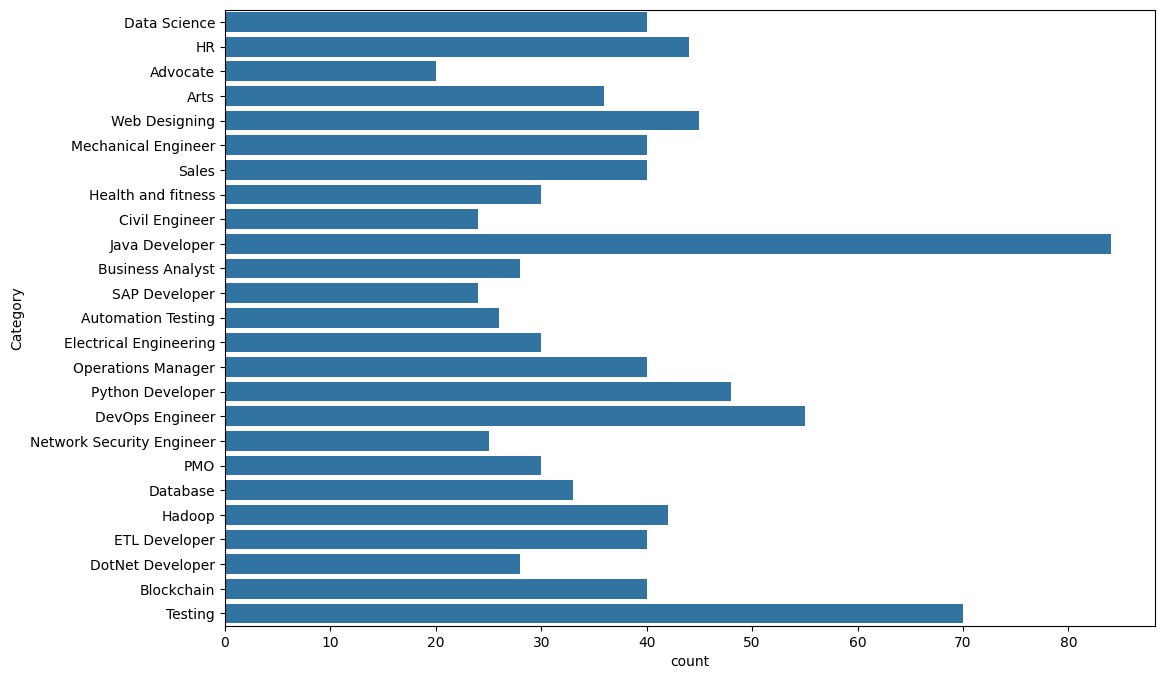

In [46]:
# Now we will plot the categories on a chart so that we can easily visualize the data 

# by countplot() 
plt.figure(figsize=(12,8))
sns.countplot(data['Category'])
plt.show()

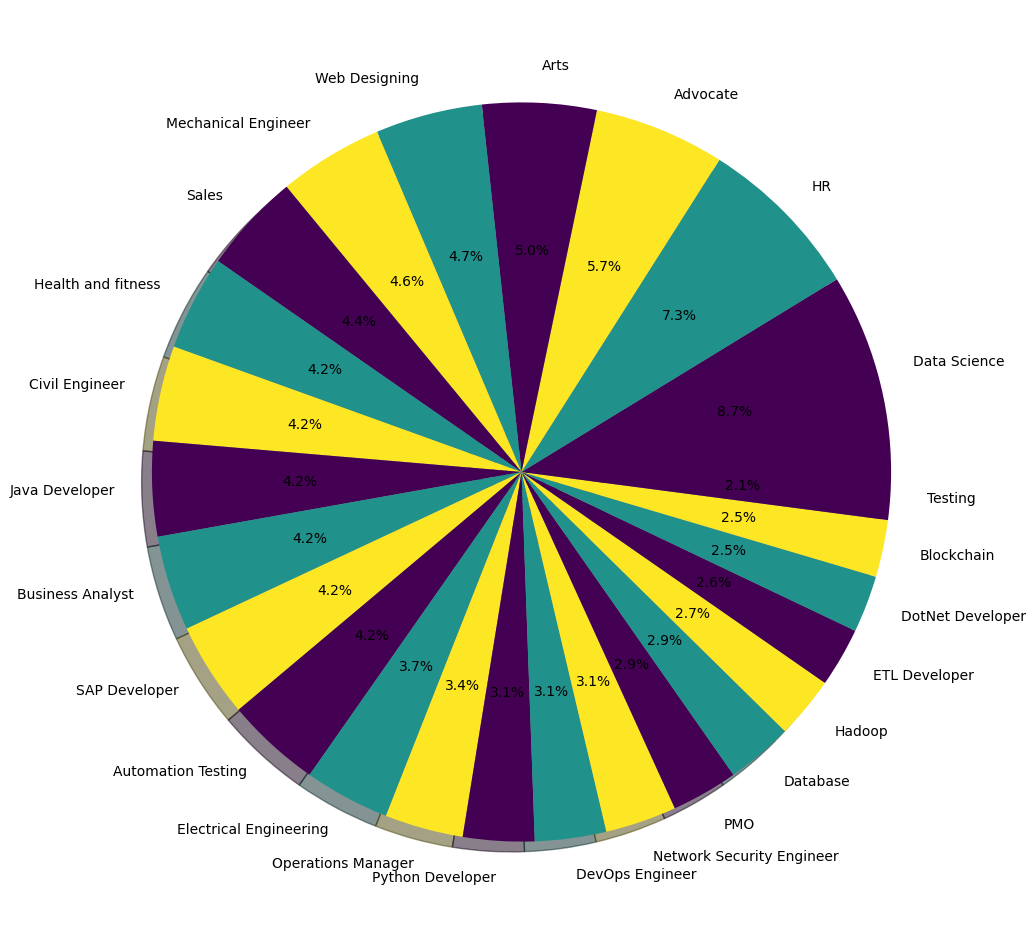

In [47]:
# now we will plot the category on the pie chart -- for pie chart we need two things (1) labels (2) count values
counts = data['Category'].value_counts()
labels = data['Category'].unique()

plt.figure(figsize=(12, 12))
# plt.pie(counts, labels=labels)

# now we will assign the value of each category in terms of percentage, so for that 

# autopct --- is an attribute used to assign the values in terms of percentage and for that we will use the specific format to show the percentage value 

''' here %1.1f%% - 
% → formatting begins
1.1f
1 = minimum width
.1 = one digit after the decimal
f = floating-point number
%% prints a literal % '''

# colors -- where np.linspace(start, stop,  num) --- np.linspace(0, 1, 3) --- it will return "array([0.0, 0.5, 1.0])" 
# Dark Purple -------- Blue -------- Yellow
# 0.0            0.5             1.0

plt.pie(counts, labels=labels, autopct='%1.1f%%', shadow=True,colors=plt.cm.viridis(np.linspace(0,1,3)))
plt.show()

In [48]:
# Now we will perform the cleaning on the dataset where we will remove the stopwords, emojis, links, special characters, etc. 

print(data['Resume'])
# print(data['Resume'][0])

0      Skills * Programming Languages: Python (pandas...
1      Education Details \r\nMay 2013 to May 2017 B.E...
2      Areas of Interest Deep Learning, Control Syste...
3      Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4      Education Details \r\n MCA   YMCAUST,  Faridab...
                             ...                        
957    Computer Skills: â¢ Proficient in MS office (...
958    â Willingness to accept the challenges. â ...
959    PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne...
960    COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...
961    Skill Set OS Windows XP/7/8/8.1/10 Database MY...
Name: Resume, Length: 962, dtype: object


In [49]:
# we will create a function to remove the urls, hashtags, mentions, punctuations and stopwords 

def cleanData(txt): 
    cleantxt = re.sub('http\S+\s','',txt) # it will used to remove the https text 
    cleantxt = re.sub('@\S+','', cleantxt) # it will used to remove the @ and email address
    cleantxt = re.sub('#\S+\s','', cleantxt) # it will used to remove the # and #1232 associated values 
    cleantxt = re.sub('RT|cc','', cleantxt) # it will used to remove the RT and cc associated values 
    cleantxt = re.sub('\s+','', cleantxt) # it will used to remove the sequence like \n, \t, etc  
    cleantxt = re.sub('[%s]'% re.escape(""" !"#$%&'()*+,-./:;<=>?@[\]^_'â¢{|}~"""),'', cleantxt) # it will used to remove the special characters values 
                
    return cleantxt 

# with the help of lambda function we will perform the cleanData function on each statement present inside the resume column
data['Resume'] = data['Resume'].apply(lambda x: cleanData(x))

<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\S'
<>:6: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\]'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\S'
<>:6: SyntaxWarning: invalid escape sequence '\S'
<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\]'
C:\Users\Admin\AppData\Local\Temp\ipykernel_10468\3627486174.py:4: SyntaxWarning: invalid escape sequence '\S'
  cleantxt = re.sub('http\S+\s','',txt) # it will used to remove the https text
C:\Users\Admin\AppData\Local\Temp\ipykernel_10468\3627486174.py:5: SyntaxWarning: invalid escape sequence '\S'
  cleantxt = re.sub('@\S+','', cleantxt) # it will used to remove the @ and email address
C:\Users\Admin\AppData\Local\Temp\ipykernel_10468\3627486174.py:6: SyntaxWarning: invalid escape sequence '\

In [50]:
print(data['Resume'][3])

SkillsRPythonSAPHANATableauSAPHANASQLSAPHANAPALMSSQLSAPLumiraCLinearProgrammingDataModellingAdvanceAnalyticsSCMAnalyticsRetailAnalyticsSocialMediaAnalyticsNLPEducationDetailsJanuary2017toJanuary2018PGDMBusinessAnalyticsGreatLakesInstituteofManagementIllinoisInstituteofTechnologyJanuary2013BachelorofEngineeringElectronicsandCommunicationBengaluruKarnatakaNewHorizonCollegeofEngineeringBangaloreVisvesvarayaTechnologicalUniversityDataScienceConsultantConsultantDeloitteUSISkillDetailsLINEARPROGRAMMINGExprience6monthsRETAILExprience6monthsRETAILMARKETINGExprience6monthsSCMExprience6monthsSQLExprienceLessthan1yearmonthsDeepLearningExprienceLessthan1yearmonthsMachinelearningExprienceLessthan1yearmonthsPythonExprienceLessthan1yearmonthsRExprienceLessthan1yearmonthsCompanyDetailscompanyDeloitteUSIdescriptionTheprojectinvolvedanalysinghistoricdealsandcomingwithinsightstooptimizefuturedealsRoleWasgivenrawdatacarriedoutendtoendanalysisandpresentedinsightstoclientKeyResponsibilitiesExtractdatafromcl

In [51]:
# now we will perform the label encoding for the Categories column where we convert the text into the given numbers 
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

le.fit(data['Category'])
data['Category'] = le.transform(data['Category'])

In [52]:
print(data['Category'].unique())

[ 6 12  0  1 24 16 22 14  5 15  4 21  2 11 18 20  8 17 19  7 13 10  9  3
 23]


In [53]:
# we want to conver the resume words into the number
from sklearn.feature_extraction.text import TfidfVectorizer 
tfidf = TfidfVectorizer(stop_words="english") # we have create an object and informing them about the english stopwords
tfidf.fit(data['Resume'])
requiredText = tfidf.transform(data['Resume'])

In [54]:
print(requiredText)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3837 stored elements and shape (962, 665)>
  Coords	Values
  (0, 483)	0.5773502691896258
  (0, 587)	0.5773502691896258
  (0, 588)	0.5773502691896258
  (1, 170)	1.0
  (2, 25)	1.0
  (3, 485)	1.0
  (4, 173)	1.0
  (5, 468)	1.0
  (6, 484)	1.0
  (7, 143)	0.25
  (7, 271)	0.5
  (7, 352)	0.5
  (7, 435)	0.25
  (7, 436)	0.25
  (7, 488)	0.25
  (7, 489)	0.5
  (8, 5)	0.5773502691896258
  (8, 246)	0.5773502691896258
  (8, 381)	0.5773502691896258
  (9, 33)	0.2182178902359924
  (9, 35)	0.2182178902359924
  (9, 41)	0.2182178902359924
  (9, 44)	0.2182178902359924
  (9, 98)	0.2182178902359924
  (9, 99)	0.2182178902359924
  :	:
  (947, 476)	1.0
  (948, 229)	1.0
  (949, 56)	1.0
  (950, 59)	1.0
  (951, 497)	0.408248290463863
  (951, 519)	0.408248290463863
  (951, 568)	0.408248290463863
  (951, 594)	0.408248290463863
  (951, 609)	0.408248290463863
  (951, 613)	0.408248290463863
  (952, 384)	1.0
  (953, 60)	1.0
  (954, 476)	1.0
  (955, 229)	1.0
  (9

In [55]:
# now we will split the data for the training and testing 
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(requiredText,data['Category'], test_size=0.20, random_state=42)

In [56]:
# to check the shape of the training and testing data 
print(X_train.shape)
print(X_test.shape)

(769, 665)
(193, 665)


In [57]:
# now we will make an algorithm to predict the values 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [58]:
# prediction for logistic regression 
predicted_value = logistic_model.predict(X_test)

# to find the accuracy score for logistic regression 
print(accuracy_score(y_test, predicted_value))

0.9689119170984456


In [59]:
print(predicted_value) # So, this is the final result which we have obtain after performing the logistic regression algorithm

[15 15 15 13 14 17 16  2 15 14 13 12 16 23 20  5  6  4 10  9 19  1 10 23
 23  6 22 22  2 12 18  1  8 24 11 23  7 12 24  8 18  6  8 19 24 23 21  1
 15  4 15 22 11  5 15 13  1 19  5 12 22 22 20 24 21 18 12 10 10 20 10  8
  9 21 17 21  0 17 16 14 15 11 11  8 20  3 19  8 15  2  9 10  2 23 20 20
 23 12 18 12  7 16  8 14 18  3 14 19 14 14 15 18  8  2 21 18 23 10 23 15
 11 15 12  3 15  3  7 12 19  8 20 15  3 15  9 19  1 23 21  5 20 15 16  7
  7  8 15 18  1 15 13 20  7  4 18 11 15 15  5 12  9 22 18 21  8 23  4 12
 24 16 15 22  8 22  3 16 23 23 12  7 16 18  5  3 18  8 23 23 20  6  6  7
 23]


In [ ]:
# ---------------------------------- Now we will use the Naive Bayes Algorithm -------------------------------------

In [60]:
from sklearn.naive_bayes import MultinomialNB # import MultinomialNB 
from sklearn.metrics import accuracy_score # import accuracy_score so that we can find the accuracy of the metrics 

# create an object of the MultinomialNB 
nb_model = MultinomialNB()

In [61]:
# now we will pass the X_train and y_train to the MultinomialNB object 
nb_model.fit(X_train, y_train)  # here we are creating a multinomialNB for the given model 

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [65]:
# now we will check the prediction for the countVectorizer in Bag of Words 
prediction_bow = nb_model.predict(X_test)

In [ ]:
# accuracy_score() function will be used for prediction 
print(accuracy_score(y_test,predicted_value)) # the accuracy comes at 0.9689 

0.9689119170984456


In [67]:
print(predicted_value)

[15 15 15 13 14 17 16  2 15 14 13 12 16 23 20  5  6  4 10  9 19  1 10 23
 23  6 22 22  2 12 18  1  8 24 11 23  7 12 24  8 18  6  8 19 24 23 21  1
 15  4 15 22 11  5 15 13  1 19  5 12 22 22 20 24 21 18 12 10 10 20 10  8
  9 21 17 21  0 17 16 14 15 11 11  8 20  3 19  8 15  2  9 10  2 23 20 20
 23 12 18 12  7 16  8 14 18  3 14 19 14 14 15 18  8  2 21 18 23 10 23 15
 11 15 12  3 15  3  7 12 19  8 20 15  3 15  9 19  1 23 21  5 20 15 16  7
  7  8 15 18  1 15 13 20  7  4 18 11 15 15  5 12  9 22 18 21  8 23  4 12
 24 16 15 22  8 22  3 16 23 23 12  7 16 18  5  3 18  8 23 23 20  6  6  7
 23]
